In [1]:
import pandas as pd
import numpy as np
import joblib
import shap
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [2]:
synthetic_df = pd.read_csv(
    "../data/synthetic-cart-data.csv"
)

print("Shape:", synthetic_df.shape)
print("\nColumns:")
print(synthetic_df.columns.tolist())

print("\nMissing values:")
print(synthetic_df.isnull().sum().sum())

print("\nTarget:")
print(synthetic_df["is_abandoned"].value_counts())

Shape: (50000, 18)

Columns:
['session_id', 'user_id', 'cart_value', 'avg_price_before_cart', 'previous_purchase_count', 'user_purchase_rate', 'days_since_last_purchase', 'checkout_page_visited', 'payment_attempted', 'payment_failed', 'shipping_cost_shown', 'coupon_code_attempted', 'coupon_applied_successfully', 'exit_intent_detected', 'time_on_payment_page_seconds', 'device_type', 'traffic_source', 'is_abandoned']

Missing values:
0

Target:
is_abandoned
1    32723
0    17277
Name: count, dtype: int64


In [3]:
drop_cols = [
    "session_id",
    "user_id",
    "is_abandoned"
]

X = synthetic_df.drop(
    columns=drop_cols
)

y = synthetic_df["is_abandoned"]

print("X:", X.shape)
print("y:", y.shape)

X: (50000, 15)
y: (50000,)


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = [
    "device_type",
    "traffic_source"
]

numeric_features = [
    col for col in X.columns
    if col not in categorical_features
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(40000, 15)
(10000, 15)


In [6]:
synthetic_logistic = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=2000,
            random_state=42
        )
    )
])

synthetic_logistic.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['cart_value','avg_price_before_cart','previous_purchase_count',..., 'time_on_payment_page_seconds','device_type','traffic_source']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (defau

In [7]:
pred = synthetic_logistic.predict(X_test)
prob = synthetic_logistic.predict_proba(X_test)[:, 1]

print("Synthetic Logistic Regression")
print("------------------------------")
print(
    "Accuracy :",
    round(accuracy_score(y_test, pred), 4)
)
print(
    "Precision:",
    round(precision_score(y_test, pred), 4)
)
print(
    "Recall   :",
    round(recall_score(y_test, pred), 4)
)
print(
    "F1 Score :",
    round(f1_score(y_test, pred), 4)
)
print(
    "ROC-AUC  :",
    round(roc_auc_score(y_test, prob), 4)
)

Synthetic Logistic Regression
------------------------------
Accuracy : 0.9031
Precision: 0.9335
Recall   : 0.9173
F1 Score : 0.9253
ROC-AUC  : 0.9692


In [8]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = cross_validate(
    synthetic_logistic,
    X,
    y,
    cv=cv,
    scoring=[
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc"
    ],
    n_jobs=-1
)

for metric in [
    "test_accuracy",
    "test_precision",
    "test_recall",
    "test_f1",
    "test_roc_auc"
]:
    print(
        metric,
        "Mean:",
        round(cv_results[metric].mean(), 4),
        "Std:",
        round(cv_results[metric].std(), 4)
    )

test_accuracy Mean: 0.9029 Std: 0.0045
test_precision Mean: 0.9311 Std: 0.0048
test_recall Mean: 0.9196 Std: 0.0038
test_f1 Mean: 0.9253 Std: 0.0034
test_roc_auc Mean: 0.9694 Std: 0.0018


In [9]:
joblib.dump(
    synthetic_logistic,
    "../models/synthetic_final_model.pkl"
)

['../models/synthetic_final_model.pkl']

In [10]:
joblib.dump(
    X.columns.tolist(),
    "../models/synthetic_feature_columns.pkl"
)

['../models/synthetic_feature_columns.pkl']

In [11]:
preprocessor_fitted = synthetic_logistic.named_steps[
    "preprocessor"
]

classifier_fitted = synthetic_logistic.named_steps[
    "classifier"
]

In [12]:
X_test_transformed = (
    preprocessor_fitted.transform(X_test)
)

In [13]:
print(X_test_transformed.shape)

(10000, 21)


In [14]:
feature_names = (
    preprocessor_fitted
    .get_feature_names_out()
)

print(len(feature_names))
print(feature_names)

21
['num__cart_value' 'num__avg_price_before_cart'
 'num__previous_purchase_count' 'num__user_purchase_rate'
 'num__days_since_last_purchase' 'num__checkout_page_visited'
 'num__payment_attempted' 'num__payment_failed' 'num__shipping_cost_shown'
 'num__coupon_code_attempted' 'num__coupon_applied_successfully'
 'num__exit_intent_detected' 'num__time_on_payment_page_seconds'
 'cat__device_type_desktop' 'cat__device_type_mobile'
 'cat__device_type_tablet' 'cat__traffic_source_direct'
 'cat__traffic_source_email' 'cat__traffic_source_organic'
 'cat__traffic_source_paid_ad' 'cat__traffic_source_social']


In [15]:
explainer = shap.LinearExplainer(
    classifier_fitted,
    X_test_transformed
)

Background dataset has 10000 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=10000 when initializing the masker.


In [16]:
shap_values = explainer(
    X_test_transformed
)

In [17]:
shap_importance = pd.Series(
    np.abs(shap_values.values).mean(axis=0),
    index=feature_names
).sort_values(
    ascending=False
)

print(
    shap_importance.head(15)
)

num__checkout_page_visited           3.744362
num__coupon_applied_successfully     1.589585
num__payment_attempted               1.298404
cat__device_type_mobile              1.078997
num__payment_failed                  1.073759
num__exit_intent_detected            1.037587
num__user_purchase_rate              0.520025
num__shipping_cost_shown             0.466903
num__coupon_code_attempted           0.375631
num__time_on_payment_page_seconds    0.341348
cat__traffic_source_paid_ad          0.341258
cat__traffic_source_social           0.333113
num__cart_value                      0.286937
num__days_since_last_purchase        0.188202
num__avg_price_before_cart           0.159403
dtype: float64


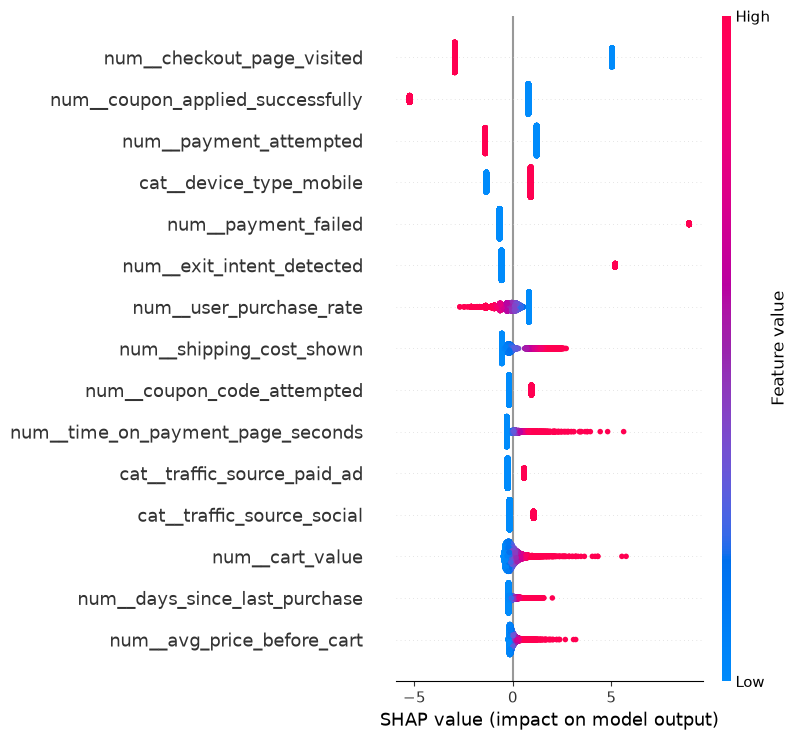

In [18]:
shap.summary_plot(
    shap_values.values,
    X_test_transformed,
    feature_names=feature_names,
    max_display=15
)

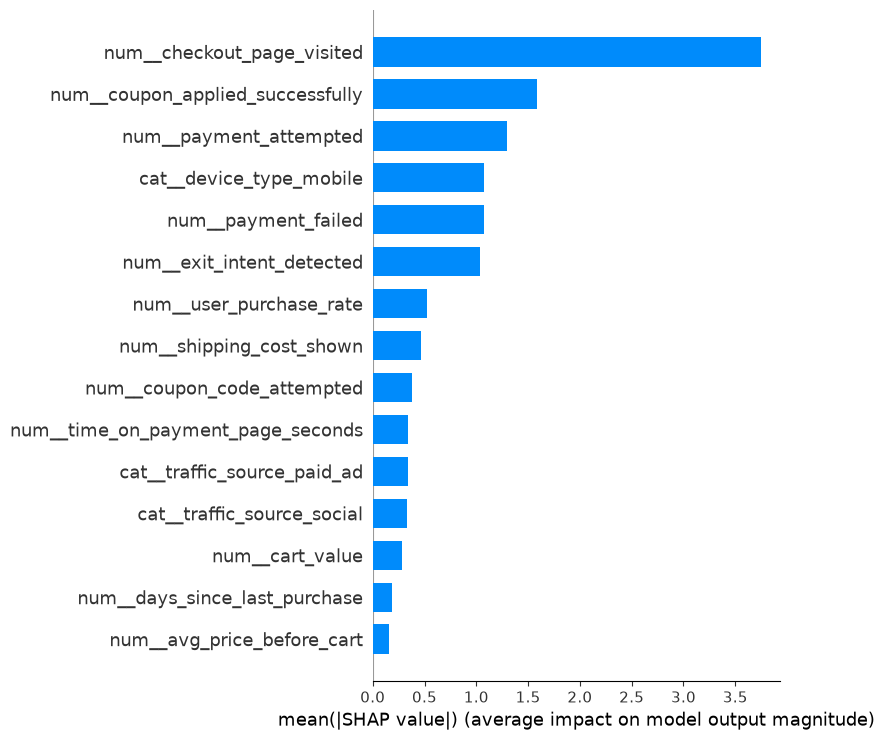

In [19]:
shap.summary_plot(
    shap_values.values,
    X_test_transformed,
    feature_names=feature_names,
    plot_type="bar",
    max_display=15
)

In [20]:
synthetic_predictions = synthetic_logistic.predict(
    X_test
)

synthetic_probabilities = (
    synthetic_logistic.predict_proba(
        X_test
    )[:, 1]
)

In [21]:
abandoned_positions = np.where(
    synthetic_predictions == 1
)[0]

best_position = abandoned_positions[
    np.argmax(
        synthetic_probabilities[
            abandoned_positions
        ]
    )
]

print(
    "Abandonment probability:",
    round(
        synthetic_probabilities[best_position],
        4
    )
)

Abandonment probability: 1.0


In [22]:
individual_shap = pd.Series(
    shap_values.values[best_position],
    index=feature_names
).sort_values(
    key=abs,
    ascending=False
)

print(
    individual_shap.head(10)
)

num__checkout_page_visited           5.024084
num__cart_value                      4.312509
num__avg_price_before_cart           3.076064
num__shipping_cost_shown             1.976634
num__payment_attempted               1.202013
cat__device_type_mobile              0.901192
num__coupon_applied_successfully     0.783807
num__payment_failed                 -0.673360
num__exit_intent_detected           -0.576694
num__time_on_payment_page_seconds   -0.311014
dtype: float64


In [23]:
original_example = X_test.iloc[best_position]

individual_explanation = pd.DataFrame({
    "feature": individual_shap.index,
    "feature_value": [
        original_example[
            feature.split("__")[-1]
        ]
        if feature.split("__")[-1]
        in original_example.index
        else "encoded"
        for feature in individual_shap.index
    ],
    "shap_value": individual_shap.values
})

print(
    individual_explanation.head(10)
)

                             feature feature_value  shap_value
0         num__checkout_page_visited             0    5.024084
1                    num__cart_value        729.49    4.312509
2         num__avg_price_before_cart         708.7    3.076064
3           num__shipping_cost_shown         39.22    1.976634
4             num__payment_attempted             0    1.202013
5            cat__device_type_mobile       encoded    0.901192
6   num__coupon_applied_successfully             0    0.783807
7                num__payment_failed             0   -0.673360
8          num__exit_intent_detected             0   -0.576694
9  num__time_on_payment_page_seconds           0.0   -0.311014


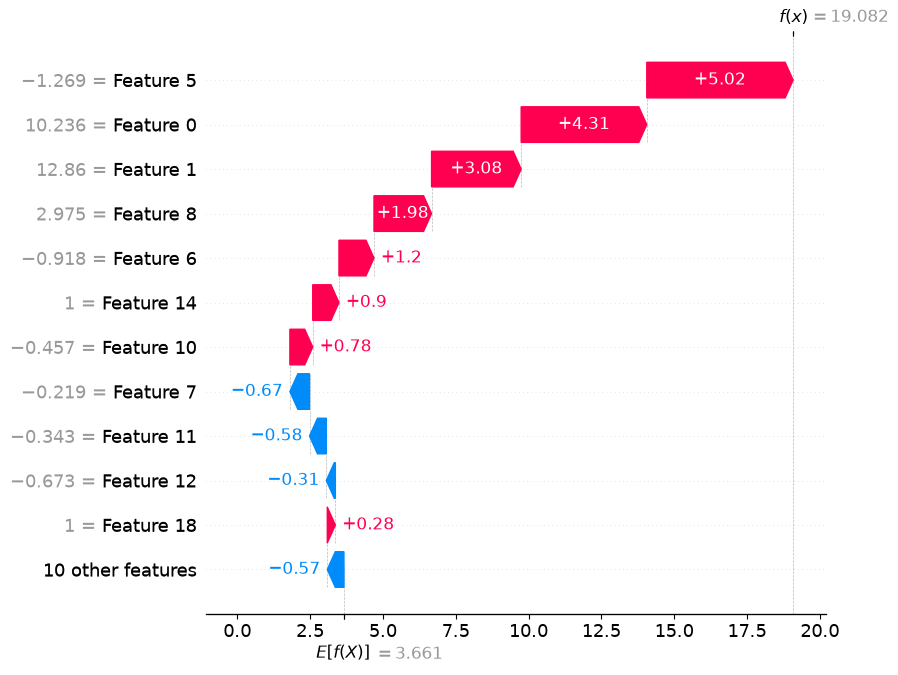

In [24]:
shap.plots.waterfall(
    shap_values[best_position],
    max_display=12
)

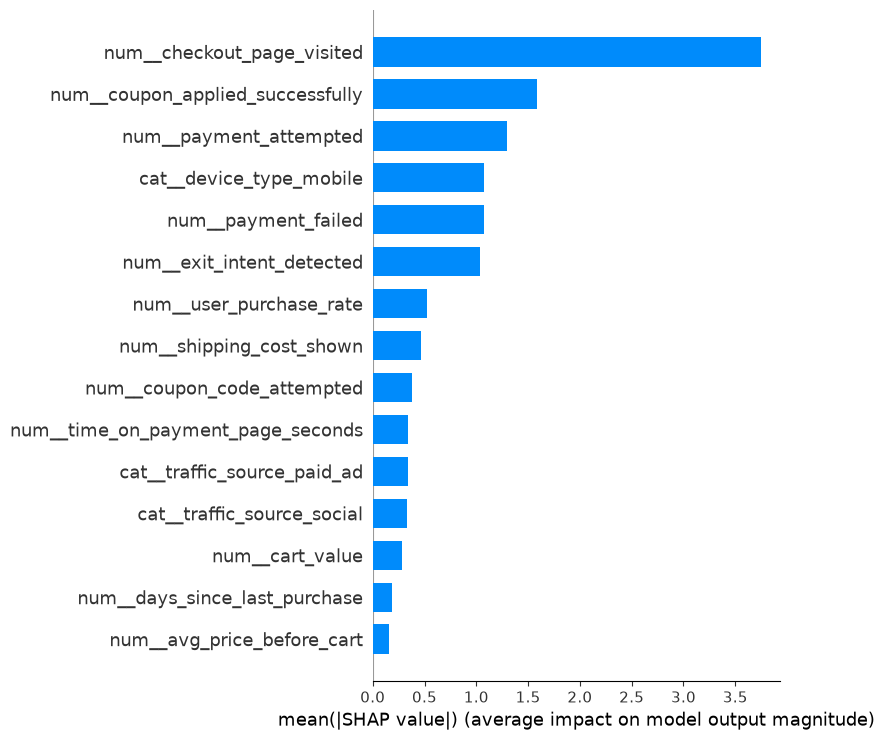

In [27]:
shap.summary_plot(
    shap_values.values,
    X_test_transformed,
    feature_names=feature_names,
    plot_type="bar",
    max_display=15
)

In [28]:
import joblib

joblib.dump(
    synthetic_logistic,
    "../models/synthetic_final_model.pkl"
)

joblib.dump(
    X.columns.tolist(),
    "../models/synthetic_feature_columns.pkl"
)

['../models/synthetic_feature_columns.pkl']